
# Notebook 05 — Model Explainability

## Objective
Explain how baseline features influence Random Forest predictions
of a 40% or greater eGFR decline at Week 52.

## Techniques
1. Random Forest Feature Importance
2. SHAP Global Feature Importance
3. SHAP Summary Plot
4. SHAP Individual Prediction Explanation

## Important
These are model explanations, not clinical diagnoses
or evidence of cause and effect.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

project_dir = Path(
    r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES"
)

data_path = (
    project_dir / "datasets" / "processed" /
    "ckd_model_ready.csv"
)

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset Shape: (4362, 8)

Columns:
['patient_id', 'baseline_egfr', 'treatment_group', 'baseline_glp1', 'ckd_progression', 'egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2', 'egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2', 'egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2']


,patient_id,baseline_egfr,treatment_group,baseline_glp1,ckd_progression,egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2,egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2,egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2
0,id0001,54,0,0,0,0,1,0
1,id0003,50,1,0,0,0,1,0
2,id0004,47,0,0,0,0,1,0
3,id0005,75,0,0,0,0,0,1
4,id0006,30,0,0,0,1,0,0


In [2]:

# Separate features and target
X = df.drop(columns=["patient_id", "ckd_progression"])
y = df["ckd_progression"]

# Clean special characters in feature names
X.columns = (
    X.columns
    .str.replace("<", "lt", regex=False)
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
)

# Same train-test split as Notebook 04
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Random Forest trained successfully!
Training shape: (3489, 6)
Testing shape: (873, 6)


Random Forest Feature Importance:


,Feature,Importance
0,baseline_egfr,0.733789
5,egfr_category_Screening eGFR 60 to lt90 mL/min...,0.145233
3,egfr_category_Screening eGFR 30 to lt45 mL/min...,0.068757
4,egfr_category_Screening eGFR 45 to lt60 mL/min...,0.033276
1,treatment_group,0.010143
2,baseline_glp1,0.008802


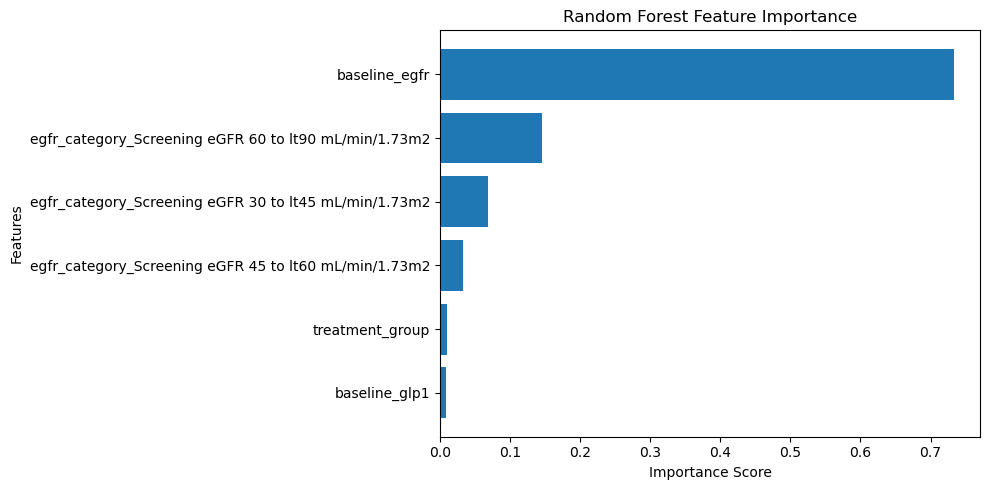

In [3]:

# Get feature importance scores
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
display(importance)

# Plot
plt.figure(figsize=(10, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [4]:

%pip install shap


   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 454.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 454.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 454.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 454.2 kB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 346.1 kB/s  0:00:02

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   

In [5]:

import shap

print("SHAP Version:", shap.__version__)
print("SHAP imported successfully!")


SHAP Version: 0.54.1
SHAP imported successfully!


In [6]:

# Select 200 testing patients for clear, fast visualizations
X_explain = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

# Create TreeExplainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
raw_shap_values = explainer.shap_values(X_explain)

# Select positive class (class 1)
if isinstance(raw_shap_values, list):
    positive_values = raw_shap_values[1]
else:
    positive_values = np.asarray(raw_shap_values)

    if positive_values.ndim == 3:
        positive_values = positive_values[:, :, 1]

# Select expected value for class 1
expected_values = np.asarray(explainer.expected_value)

if expected_values.ndim > 0:
    base_value = float(expected_values[1])
else:
    base_value = float(expected_values)

# Create a standard SHAP Explanation object
shap_explanation = shap.Explanation(
    values=positive_values,
    base_values=np.full(len(X_explain), base_value),
    data=X_explain.to_numpy(),
    feature_names=X_explain.columns.tolist()
)

print("SHAP values calculated successfully!")
print("SHAP shape:", positive_values.shape)


SHAP values calculated successfully!
SHAP shape: (200, 6)


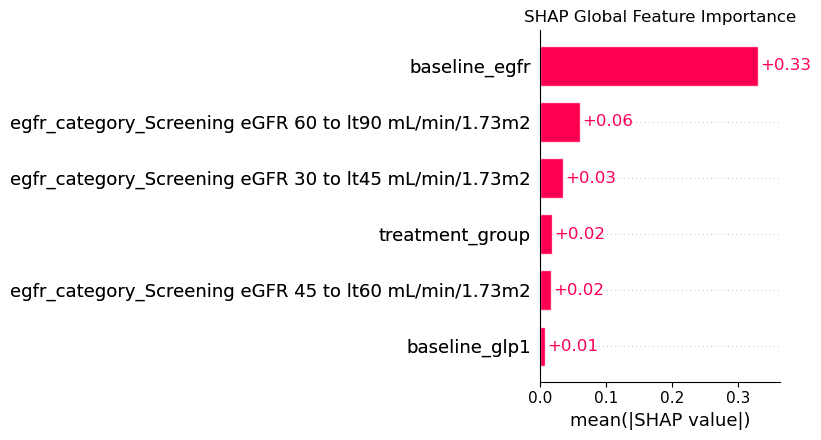

In [7]:

# SHAP global importance
shap.plots.bar(
    shap_explanation,
    max_display=10,
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()
plt.show()


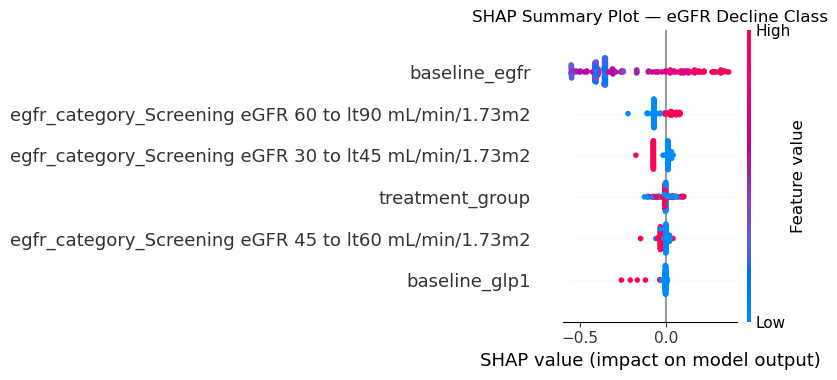

In [8]:

# SHAP summary plot
shap.plots.beeswarm(
    shap_explanation,
    max_display=10,
    show=False
)

plt.title("SHAP Summary Plot — eGFR Decline Class")
plt.tight_layout()
plt.show()


Predicted Class: 1
Predicted Probability of Class 1: 0.6519

Patient Baseline Features:


,baseline_egfr,treatment_group,baseline_glp1,egfr_category_Screening eGFR 30 to lt45 mL/min/1.73m2,egfr_category_Screening eGFR 45 to lt60 mL/min/1.73m2,egfr_category_Screening eGFR 60 to lt90 mL/min/1.73m2
3937,73,1,0,0,1,0


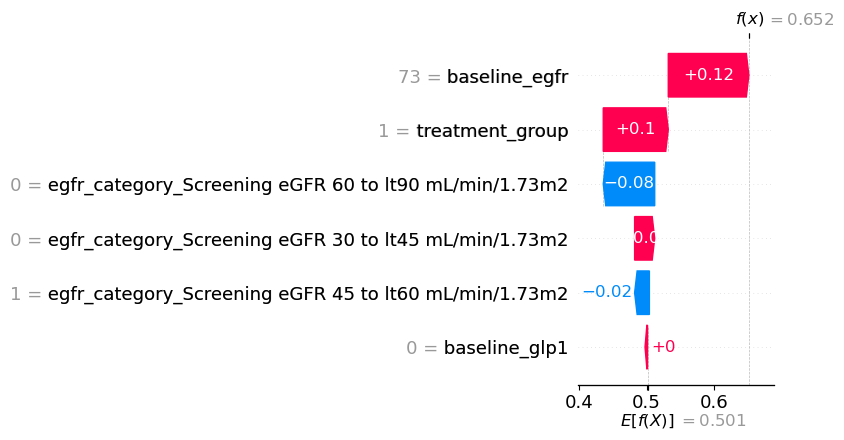

In [9]:

# Select a patient predicted to be in class 1,
# if one is available in the explanation sample.

predictions = rf_model.predict(X_explain)

positive_indices = np.where(predictions == 1)[0]

if len(positive_indices) > 0:
    patient_index = int(positive_indices[0])
else:
    patient_index = 0

patient = X_explain.iloc[[patient_index]]

prediction = rf_model.predict(patient)[0]
probability = rf_model.predict_proba(patient)[0, 1]

print("Predicted Class:", prediction)
print("Predicted Probability of Class 1:",
      round(probability, 4))

print("\nPatient Baseline Features:")
display(patient)

# Waterfall plot
shap.plots.waterfall(
    shap_explanation[patient_index],
    max_display=10,
    show=False
)

plt.tight_layout()
plt.show()


In [10]:

# Calculate average absolute SHAP values
mean_shap = np.abs(positive_values).mean(axis=0)

comparison = pd.DataFrame({
    "Feature": X_explain.columns,
    "Random_Forest_Importance": rf_model.feature_importances_,
    "Mean_Absolute_SHAP": mean_shap
})

comparison = comparison.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("Feature Importance Comparison:")
display(comparison.round(4))


Feature Importance Comparison:


,Feature,Random_Forest_Importance,Mean_Absolute_SHAP
0,baseline_egfr,0.7338,0.3301
5,egfr_category_Screening eGFR 60 to lt90 mL/min...,0.1452,0.0602
3,egfr_category_Screening eGFR 30 to lt45 mL/min...,0.0688,0.0341
1,treatment_group,0.0101,0.0179
4,egfr_category_Screening eGFR 45 to lt60 mL/min...,0.0333,0.0158
2,baseline_glp1,0.0088,0.0065



## Conclusion

In this notebook, we explained Random Forest predictions using
feature importance and SHAP.

### Completed
- Random Forest feature importance chart
- SHAP global importance chart
- SHAP summary plot
- Individual prediction waterfall plot
- Comparison of feature importance methods

### Limitations
- The model predicts a 40% or greater eGFR decline at Week 52,
  not a confirmed diagnosis of CKD.
- The dataset contains limited baseline predictors.
- Patients without selected Week 52 measurements were excluded.
- SHAP explanations describe model behavior, not causation.
- Results are based on a single train-test split.

These explanations help us understand which available baseline
features the model uses when making predictions.
